# 1. Condiciones y cota de iteraciones

## Algoritmo 2.1 (Método Bisección)

In [24]:
def f(x):
    return x**3 - x - 1

def biseccion(f, a, b, TOL, N0=100): 
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a+(b-a)/2                                    
        FP = f(p)
        historia.append((a,b,p))                      
        if FP == 0 or (b-a)/2 < TOL:                          
            return p, historia
        i = i + 1
        if FA * FP > 0:
            a = p
            FA = FP                                   
        else:
            b = p                                    
    raise RuntimeError(f"fracasó después de {N0} iteraciones")

biseccion(f, 1, 2, 1e-4)

(1.32476806640625,
 [(1, 2, 1.5),
  (1, 1.5, 1.25),
  (1.25, 1.5, 1.375),
  (1.25, 1.375, 1.3125),
  (1.3125, 1.375, 1.34375),
  (1.3125, 1.34375, 1.328125),
  (1.3125, 1.328125, 1.3203125),
  (1.3203125, 1.328125, 1.32421875),
  (1.32421875, 1.328125, 1.326171875),
  (1.32421875, 1.326171875, 1.3251953125),
  (1.32421875, 1.3251953125, 1.32470703125),
  (1.32470703125, 1.3251953125, 1.324951171875),
  (1.32470703125, 1.324951171875, 1.3248291015625),
  (1.32470703125, 1.3248291015625, 1.32476806640625)])

# 2. Raíces con el Algoritmo 2.1

In [ ]:
def f(x):
    return x**3 - 7*x**2 + 14*x - 6

intervalos = [(0, 1), (1, 3.2), (3.2, 4)]

for a, b in intervalos:
    p, historia = biseccion(f, a, b, 1e-2)

    print(f"Intervalo [{a}, {b}]")
    print(f"Raíz: {p:.12f}")
    print(f"Iteraciones: {len(historia)}")
    print()

Intervalo [0, 1]
Raíz: 0.585937500000
Iteraciones: 7

Intervalo [1, 3.2]
Raíz: 3.002343750000
Iteraciones: 8

Intervalo [3.2, 4]
Raíz: 3.418750000000
Iteraciones: 7



In [12]:
import math

def f(x):
    return x - 2*math.sin(x)

p, historia = biseccion(f, 1, 2, TOL=1e-5)

print(f"{p:.12f}")

1.895500183105


In [13]:
def f(x):
    return x - math.tan(x)

p, historia = biseccion(f, 4, 4.5, TOL=1e-5)

print(f"{p:.12f}")

4.493415832520


In [15]:
def f(x):
    return x**2 - 1 - math.exp(1-x**2)

p, historia = biseccion(f, -2, 0, TOL=1e-3)

print(f"{p:.12f}")

-1.250976562500


# 3.Raices multiples

In [21]:
def f(x):
    return (x+3)*(x+1)**2*x*(x-1)**3*(x-3)

intervalos = [
    (-3.5, 2.5),
    (-1.5, 0.6),
    (0.4, 2.2),
    (2, 3.7)
]

for a, b in intervalos:
    p, historia = biseccion(f, a, b, TOL=1e-6)

    print(f"Intervalo [{a}, {b}]")
    print(f"Raíz aproximada: {p:.12f}")
    print(f"Iteraciones: {len(historia)}")
    print()

Intervalo [-3.5, 2.5]
Raíz aproximada: -2.999999761581
Iteraciones: 23

Intervalo [-1.5, 0.6]
Raíz aproximada: -0.000000214577
Iteraciones: 22

Intervalo [0.4, 2.2]
Raíz aproximada: 1.000000286102
Iteraciones: 21

Intervalo [2, 3.7]
Raíz aproximada: 3.000000143051
Iteraciones: 21



## Comprobación del comportamiento en la raíz doble x = -1

In [22]:
print("Evaluación alrededor de x = -1")

print(f"f(-1.1) = {f(-1.1):.12f}")
print(f"f(-1.0) = {f(-1.0):.12f}")
print(f"f(-0.9) = {f(-0.9):.12f}")

print("La función no cambia de signo alrededor de x = -1")

Evaluación alrededor de x = -1
f(-1.1) = -0.793575090000
f(-1.0) = -0.000000000000
f(-0.9) = -0.505576890000
La función no cambia de signo alrededor de x = -1


# 4. Problemas aplicados

In [20]:
import math

def f(h):
    L = 10
    r = 1
    V = 12.4

    return L * (
        0.5 * math.pi * r**2
        - r**2 * math.asin(h/r)
        - h * math.sqrt(r**2 - h**2)
    ) - V

h, historia = biseccion(f, 0, 1, TOL=0.01)

print(f"h = {1-h:.12f}")
print(f"Iteraciones = {len(historia)}")

h = 0.835937500000
Iteraciones = 7


In [17]:
def f(t):
    s0 = 300
    m = 0.25
    k = 0.1
    g = 9.81

    return (
        s0
        - (m*g/k)*t
        + (m**2*g/k**2)*(1-math.exp(-k*t/m))
    )

t, historia = biseccion(f, 0, 30, TOL=0.01)

print(f"Tiempo = {t:.12f}")
print(f"Iteraciones = {len(historia)}")

Tiempo = 14.729003906250
Iteraciones = 12


# 5. Gráfica

In [18]:
def biseccion(f, a, b, TOL=1e-4, N0=100):
    """
    Implementación del Algoritmo 2.1.

    Devuelve:
        p: raíz aproximada.
        historia: lista de tuplas (a, b, p).
    """

    # Validación de parámetros
    if a >= b:
        raise ValueError("El intervalo debe cumplir a < b")

    if TOL <= 0:
        raise ValueError("La tolerancia debe ser positiva")

    if not isinstance(N0, int) or N0 <= 0:
        raise ValueError("N0 debe ser un entero positivo")

    FA = f(a)
    FB = f(b)

    # Comprobar si un extremo es raíz
    if FA == 0:
        return a, []

    if FB == 0:
        return b, []

    # Validar el cambio de signo
    if FA * FB > 0:
        raise ValueError(
            "No existe cambio de signo en el intervalo"
        )

    historia = []
    i = 1

    while i <= N0:

        p = a + (b-a)/2
        FP = f(p)

        historia.append((a, b, p))

        if FP == 0 or (b-a)/2 < TOL:
            return p, historia

        i = i + 1

        if FA * FP > 0:
            a = p
            FA = FP
        else:
            b = p

    raise RuntimeError(
        f"Fracasó después de {N0} iteraciones"
    )

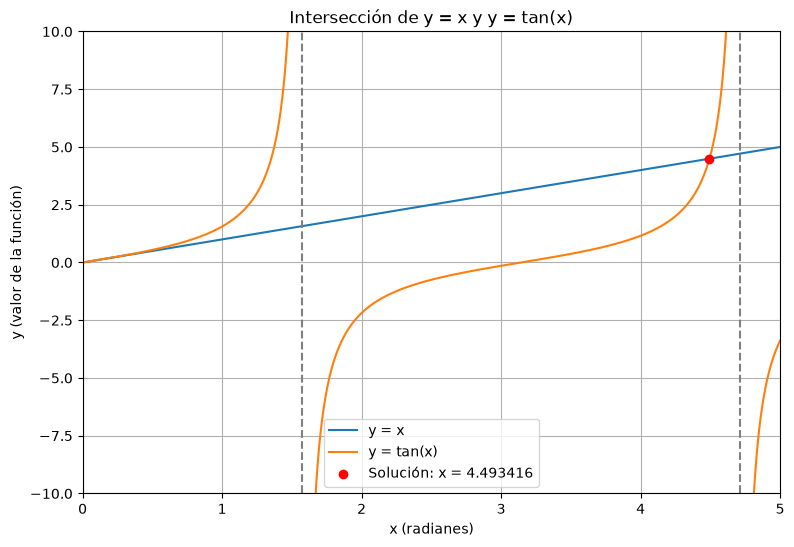

In [25]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 5, 4000)

y1 = x
y2 = np.tan(x)

# Evitar unir las ramas a través de las asíntotas
y2[np.abs(np.cos(x)) < 0.025] = np.nan

# Raíz obtenida mediante bisección
def f(x):
    return x - np.tan(x)

raiz, historia = biseccion(f, 4, 4.5, TOL=1e-5)

plt.figure(figsize=(9, 6))

plt.plot(x, y1, label="y = x")
plt.plot(x, y2, label="y = tan(x)")

# Marcar la solución
plt.scatter(
    raiz, raiz,
    color="red",
    label=f"Solución: x = {raiz:.6f}",
    zorder=5
)

# Asíntotas verticales
plt.axvline(np.pi/2, color="gray", linestyle="--")
plt.axvline(3*np.pi/2, color="gray", linestyle="--")

plt.xlim(0, 5)
plt.ylim(-10, 10)

plt.xlabel("x (radianes)")
plt.ylabel("y (valor de la función)")

plt.title("Intersección de y = x y y = tan(x)")
plt.legend()
plt.grid(True)

plt.savefig("grafica_biseccion.png", dpi=300)
plt.show()